In [1]:
import os
import sys
import torch

print("Python executable:", sys.executable)
print("Working directory:", os.getcwd())
print("PyTorch version:", torch.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Python executable: d:\Semester 5\Animal_Classifier_CNN\.venv\Scripts\python.exe
Working directory: d:\Semester 5\Animal_Classifier_CNN\Model_B
PyTorch version: 2.14.1+cpu
Device: CPU


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "Data"
IMAGE_DIR = DATA_DIR / "raw-img"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", IMAGE_DIR)
print("Dataset directory exists:", IMAGE_DIR.exists())

Project directory: d:\Semester 5\Animal_Classifier_CNN
Dataset directory: d:\Semester 5\Animal_Classifier_CNN\Data\raw-img
Dataset directory exists: True


In [6]:
class_dirs = sorted(
    folder for folder in IMAGE_DIR.iterdir()
    if folder.is_dir()
)

print("Number of classes:", len(class_dirs))
print("\nAnimal classes:")

for folder in class_dirs:
    print("-", folder.name)

Number of classes: 10

Animal classes:
- Butterfly
- Cat
- Chicken
- Cow
- Dog
- Elephant
- Horse
- Sheep
- Spider
- Squirrel


In [7]:
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = {}

for folder in class_dirs:
    images = [
        file for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ]
    class_counts[folder.name] = len(images)

print("Image counts per class:\n")

for class_name, count in class_counts.items():
    print(f"{class_name:15s}: {count:,}")

print("\nTotal images:", f"{sum(class_counts.values()):,}")

Image counts per class:

Butterfly      : 2,112
Cat            : 1,668
Chicken        : 3,098
Cow            : 1,866
Dog            : 4,863
Elephant       : 1,446
Horse          : 2,623
Sheep          : 1,820
Spider         : 4,821
Squirrel       : 1,862

Total images: 26,179


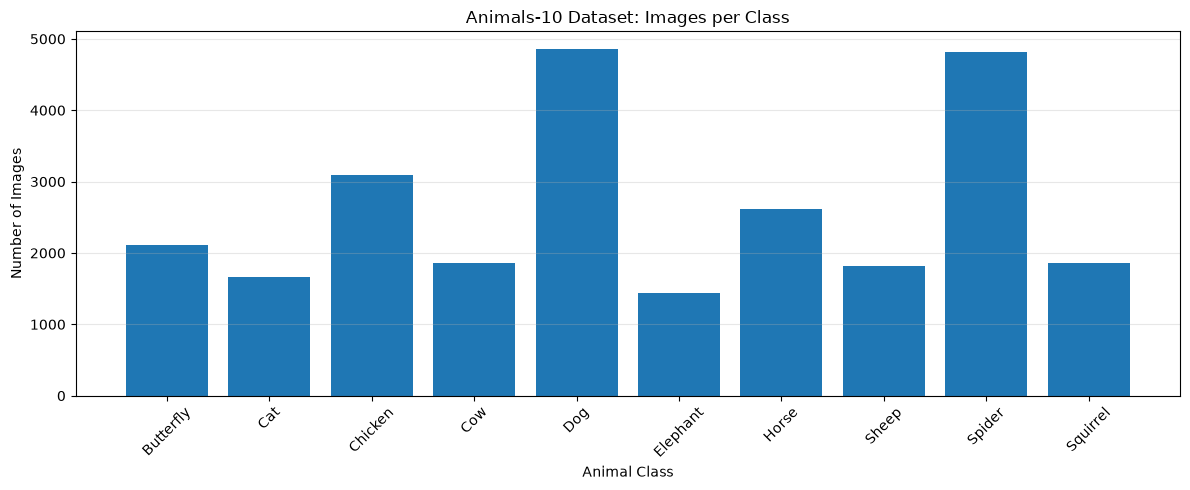

In [8]:
import matplotlib.pyplot as plt

class_names = list(class_counts.keys())
image_counts = list(class_counts.values())

plt.figure(figsize=(12, 5))
plt.bar(class_names, image_counts)
plt.title("Animals-10 Dataset: Images per Class")
plt.xlabel("Animal Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

total_checked = 0
corrupted_images = []

for folder in class_dirs:
    for file in folder.rglob("*"):
        if file.is_file() and file.suffix.lower() in image_extensions:
            total_checked += 1

            try:
                with Image.open(file) as img:
                    img.verify()
            except Exception as e:
                corrupted_images.append((str(file), str(e)))

print("Images checked:", total_checked)
print("Unreadable images:", len(corrupted_images))

if corrupted_images:
    print("\nFirst 10 unreadable images:")
    for path, error in corrupted_images[:10]:
        print(path, "->", error)

Images checked: 26179
Unreadable images: 0


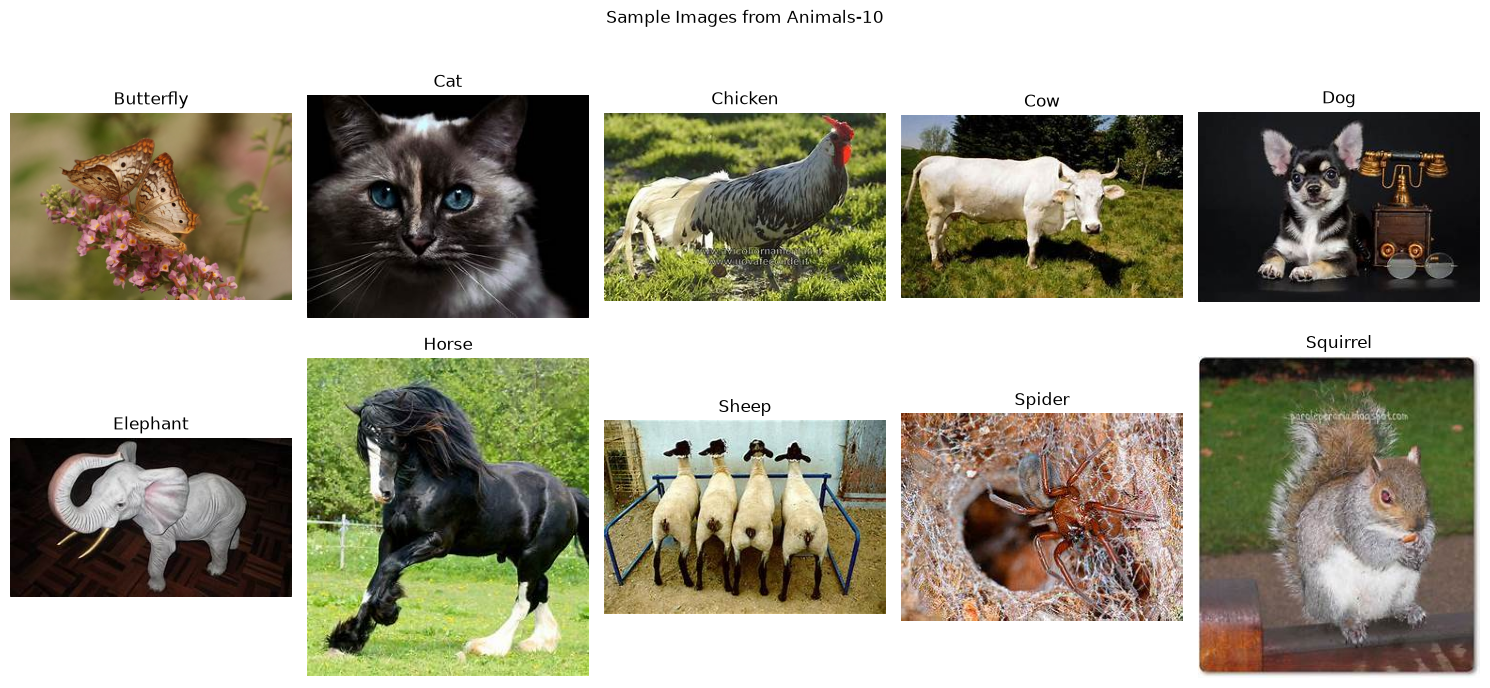

In [10]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, folder in zip(axes.flat, class_dirs):
    image_files = [
        file for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    if not image_files:
        ax.set_title(folder.name)
        ax.text(0.5, 0.5, "No images", ha="center", va="center")
        ax.axis("off")
        continue

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    display_name = "Squirrel" if folder.name == "Squrrel" else folder.name
    ax.set_title(display_name)
    ax.axis("off")

plt.suptitle("Sample Images from Animals-10")
plt.tight_layout()
plt.show()

## Create class-label mapping


In [11]:
class_names = [
    "Butterfly",
    "Cat",
    "Chicken",
    "Cow",
    "Dog",
    "Elephant",
    "Horse",
    "Sheep",
    "Spider",
    "Squirrel",
]

folder_to_label = {
    folder.name: class_names.index(
        "Squirrel" if folder.name == "Squrrel" else folder.name
    )
    for folder in class_dirs
}

label_to_class = {
    index: name for index, name in enumerate(class_names)
}

print("Class-label mapping:")

for folder_name in sorted(folder_to_label):
    print(f"{folder_name:12s} -> {folder_to_label[folder_name]}")

print("\nNumber of classes:", len(class_names))

Class-label mapping:
Butterfly    -> 0
Cat          -> 1
Chicken      -> 2
Cow          -> 3
Dog          -> 4
Elephant     -> 5
Horse        -> 6
Sheep        -> 7
Spider       -> 8
Squirrel     -> 9

Number of classes: 10


In [12]:
image_paths = []
image_labels = []

for folder in class_dirs:
    label = folder_to_label[folder.name]

    for file in sorted(folder.rglob("*")):
        if file.is_file() and file.suffix.lower() in image_extensions:
            image_paths.append(str(file))
            image_labels.append(label)

print("Total image paths:", len(image_paths))
print("Total labels:", len(image_labels))
print("First image path:", image_paths[0])
print("First image label:", image_labels[0])

Total image paths: 26179
Total labels: 26179
First image path: d:\Semester 5\Animal_Classifier_CNN\Data\raw-img\Butterfly\e030b20928e90021d85a5854ee454296eb70e3c818b413449df6c87ca3ed_640.jpg
First image label: 0


## Stratified train/validation/test split

In [13]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=image_labels,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=y_temp,
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Total images:", len(X_train) + len(X_val) + len(X_test))

Training images: 18325
Validation images: 3927
Test images: 3927
Total images: 26179


In [15]:
from collections import Counter
import pandas as pd

train_counts = Counter(y_train)
val_counts = Counter(y_val)
test_counts = Counter(y_test)

distribution = pd.DataFrame({
    "Class": class_names,
    "Training": [train_counts[i] for i in range(len(class_names))],
    "Validation": [val_counts[i] for i in range(len(class_names))],
    "Testing": [test_counts[i] for i in range(len(class_names))],
})

distribution["Total"] = (
    distribution["Training"]
    + distribution["Validation"]
    + distribution["Testing"]
)

print(distribution.to_string(index=False))
print("\nTotal images:", distribution["Total"].sum())

    Class  Training  Validation  Testing  Total
Butterfly      1478         317      317   2112
      Cat      1168         250      250   1668
  Chicken      2169         464      465   3098
      Cow      1306         280      280   1866
      Dog      3404         730      729   4863
 Elephant      1012         217      217   1446
    Horse      1836         393      394   2623
    Sheep      1274         273      273   1820
   Spider      3375         723      723   4821
 Squirrel      1303         280      279   1862

Total images: 26179


save the dataset which we split

In [16]:
import json
import pandas as pd
from pathlib import Path

SPLIT_DIR = PROJECT_DIR / "Model_B" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Store relative paths so the split file works on other computers.
def relative_paths(paths):
    return [
        Path(path).relative_to(PROJECT_DIR).as_posix()
        for path in paths
    ]

split_data = pd.DataFrame({
    "image_path": (
        relative_paths(X_train)
        + relative_paths(X_val)
        + relative_paths(X_test)
    ),
    "label": y_train + y_val + y_test,
    "split": (
        ["train"] * len(X_train)
        + ["validation"] * len(X_val)
        + ["test"] * len(X_test)
    ),
})

split_csv = SPLIT_DIR / "animals10_split_seed42.csv"
split_data.to_csv(split_csv, index=False)

# Save the label mapping too.
mapping_json = SPLIT_DIR / "class_mapping.json"

with open(mapping_json, "w", encoding="utf-8") as f:
    json.dump(
        {
            "class_names": class_names,
            "folder_to_label": folder_to_label,
            "label_to_class": label_to_class,
            "random_seed": RANDOM_SEED,
        },
        f,
        indent=4,
    )

print("Split saved to:", split_csv)
print("Label mapping saved to:", mapping_json)
print("\nSplit counts:")
print(split_data["split"].value_counts())
print("\nTotal records:", len(split_data))

Split saved to: d:\Semester 5\Animal_Classifier_CNN\Model_B\splits\animals10_split_seed42.csv
Label mapping saved to: d:\Semester 5\Animal_Classifier_CNN\Model_B\splits\class_mapping.json

Split counts:
split
train         18325
validation     3927
test           3927
Name: count, dtype: int64

Total records: 26179


verify the saved split


In [17]:
saved_split = pd.read_csv(split_csv)

print("Total records:", len(saved_split))
print("\nSubset counts:")
print(saved_split["split"].value_counts())

print("\nMissing values:")
print(saved_split.isnull().sum())

print("\nDuplicate image paths:", saved_split["image_path"].duplicated().sum())

print("\nImages per class and subset:")
print(
    pd.crosstab(
        saved_split["label"],
        saved_split["split"]
    )
)

assert len(saved_split) == 26179
assert saved_split["image_path"].isnull().sum() == 0
assert saved_split["label"].isnull().sum() == 0
assert saved_split["image_path"].duplicated().sum() == 0
assert set(saved_split["split"]) == {"train", "validation", "test"}

print("\nAll split checks passed.")

Total records: 26179

Subset counts:
split
train         18325
validation     3927
test           3927
Name: count, dtype: int64

Missing values:
image_path    0
label         0
split         0
dtype: int64

Duplicate image paths: 0

Images per class and subset:
split  test  train  validation
label                         
0       317   1478         317
1       250   1168         250
2       465   2169         464
3       280   1306         280
4       729   3404         730
5       217   1012         217
6       394   1836         393
7       273   1274         273
8       723   3375         723
9       279   1303         280

All split checks passed.
